# Reporte de Interpretabilidad: Proyecto SOLARIS

## Módulo 4: QUANTUM ANALYTICS

In [1]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split

plt.rcParams['figure.dpi'] = 150

print("SHAP:", shap.__version__)
print("Librerías importadas correctamente.")

SHAP: 0.52.0
Librerías importadas correctamente.


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "artifacts"
    / "solaris_rf_v1_20260916.joblib"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "solaris_datos_limpios.csv"
)

print("Raíz del proyecto:", PROJECT_ROOT)
print("Modelo:", MODEL_PATH)
print("Datos:", DATA_PATH)
print("¿Existe modelo?:", MODEL_PATH.exists())
print("¿Existen datos?:", DATA_PATH.exists())

Raíz del proyecto: c:\Users\anaso\Downloads\proyecto-solaris
Modelo: c:\Users\anaso\Downloads\proyecto-solaris\models\artifacts\solaris_rf_v1_20260916.joblib
Datos: c:\Users\anaso\Downloads\proyecto-solaris\data\processed\solaris_datos_limpios.csv
¿Existe modelo?: True
¿Existen datos?: True


In [3]:
modelo = joblib.load(MODEL_PATH)

print("Tipo del modelo:")
print(type(modelo))

Tipo del modelo:
<class 'sklearn.pipeline.Pipeline'>


In [4]:
df = pd.read_csv(DATA_PATH)

df_modelo = df[
    df["estado_cuenta"].isin(["Al día", "Moroso"])
].copy()

df_modelo["mora"] = df_modelo["estado_cuenta"].map({
    "Al día": 0,
    "Moroso": 1
})

features = [
    "edad",
    "ingreso_mensual",
    "saldo_actual",
    "cuotas_pagadas",
    "cuotas_totales",
    "score_externo",
    "nivel_educativo",
    "ciudad"
]

X = df_modelo[features].copy()
y = df_modelo["mora"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
    shuffle=True
)

print("Dimensiones X_test:", X_test.shape)
print("Dimensiones y_test:", y_test.shape)

Dimensiones X_test: (2460, 8)
Dimensiones y_test: (2460,)


In [5]:
X_TEST_PATH = PROJECT_ROOT / "data" / "processed" / "X_test.csv"
Y_TEST_PATH = PROJECT_ROOT / "data" / "processed" / "y_test.csv"

X_test.to_csv(X_TEST_PATH, index=False)
y_test.to_frame(name="mora").to_csv(Y_TEST_PATH, index=False)

print("X_test guardado en:", X_TEST_PATH)
print("y_test guardado en:", Y_TEST_PATH)

X_test guardado en: c:\Users\anaso\Downloads\proyecto-solaris\data\processed\X_test.csv
y_test guardado en: c:\Users\anaso\Downloads\proyecto-solaris\data\processed\y_test.csv


In [6]:
X_test = pd.read_csv(X_TEST_PATH)
y_test = pd.read_csv(Y_TEST_PATH)["mora"]

print("Tipo del modelo:", type(modelo))
print("Dimensiones de X_test:", X_test.shape)
print("Dimensiones de y_test:", y_test.shape)

Tipo del modelo: <class 'sklearn.pipeline.Pipeline'>
Dimensiones de X_test: (2460, 8)
Dimensiones de y_test: (2460,)


In [7]:
print("Componentes del pipeline:")
print(modelo.named_steps)

Componentes del pipeline:
{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['edad', 'ingreso_mensual', 'saldo_actual',
                                  'cuotas_pagadas', 'cuotas_totales',
                                  'score_externo']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['nivel_educativo', 'ciudad'])]), 'classifier': RandomForestClassifier(max_depth=20, min_samples_leaf=2, n_esti

In [8]:
preprocessor = modelo.named_steps["preprocessor"]
modelo_rf = modelo.named_steps["classifier"]

print("Preprocesador:", type(preprocessor))
print("Modelo para SHAP:", type(modelo_rf))

Preprocesador: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Modelo para SHAP: <class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [9]:
X_test_transformado = preprocessor.transform(X_test)

print("Dimensión X_test original:", X_test.shape)
print("Dimensión X_test transformado:", X_test_transformado.shape)

Dimensión X_test original: (2460, 8)
Dimensión X_test transformado: (2460, 41)


In [10]:
feature_names = preprocessor.get_feature_names_out()

print("Número de variables transformadas:", len(feature_names))
print("\nVariables:")
print(feature_names)

Número de variables transformadas: 41

Variables:
['num__edad' 'num__ingreso_mensual' 'num__saldo_actual'
 'num__cuotas_pagadas' 'num__cuotas_totales' 'num__score_externo'
 'cat__nivel_educativo_Posgrado' 'cat__nivel_educativo_Primaria'
 'cat__nivel_educativo_Secundaria' 'cat__nivel_educativo_Tecnólogo'
 'cat__nivel_educativo_Técnico' 'cat__nivel_educativo_Universitario'
 'cat__ciudad_B/Manga' 'cat__ciudad_B/Quilla' 'cat__ciudad_Baq'
 'cat__ciudad_Barranqilla' 'cat__ciudad_Barranquilla' 'cat__ciudad_Bga'
 'cat__ciudad_Bog' 'cat__ciudad_Bogotá' 'cat__ciudad_Bta'
 'cat__ciudad_Bucaramanga' 'cat__ciudad_Cal' 'cat__ciudad_Cali'
 'cat__ciudad_Cartagena' 'cat__ciudad_Cúcuta' 'cat__ciudad_Ibagué'
 'cat__ciudad_Manizales' 'cat__ciudad_Mdl' 'cat__ciudad_Med.'
 'cat__ciudad_Medellín' 'cat__ciudad_Mzl' 'cat__ciudad_Pei'
 'cat__ciudad_Pereira' 'cat__ciudad_San José De Cúcuta'
 'cat__ciudad_Santa Marta' 'cat__ciudad_Santiago De Cali'
 'cat__ciudad_Smr' 'cat__ciudad_Sta Marta' 'cat__ciudad_Villavice

In [11]:
if hasattr(X_test_transformado, "toarray"):
    X_test_transformado = X_test_transformado.toarray()

X_test_shap = pd.DataFrame(
    X_test_transformado,
    columns=feature_names,
    index=X_test.index
)

print("Dimensiones para SHAP:", X_test_shap.shape)
X_test_shap.head()

Dimensiones para SHAP: (2460, 41)


,num__edad,num__ingreso_mensual,num__saldo_actual,num__cuotas_pagadas,num__cuotas_totales,num__score_externo,cat__nivel_educativo_Posgrado,cat__nivel_educativo_Primaria,cat__nivel_educativo_Secundaria,cat__nivel_educativo_Tecnólogo,...,cat__ciudad_Mzl,cat__ciudad_Pei,cat__ciudad_Pereira,cat__ciudad_San José De Cúcuta,cat__ciudad_Santa Marta,cat__ciudad_Santiago De Cali,cat__ciudad_Smr,cat__ciudad_Sta Marta,cat__ciudad_Villavicencio,cat__ciudad_Villavo
0,0.263841,0.070490,-0.629513,-0.228194,-1.252756,0.287070,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-1.473597,-0.500249,-0.098887,-0.734149,-0.833010,0.181181,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.894451,-0.875934,-0.320398,-0.430576,0.006484,-0.626220,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.032183,-0.489792,1.018702,-0.734149,-0.413263,0.012421,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.315305,-0.227803,0.666253,1.492053,1.685471,-0.659311,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
explainer = shap.TreeExplainer(modelo_rf)

shap_values_raw = explainer.shap_values(X_test_shap)

print("SHAP values calculados correctamente.")
print("Tipo devuelto:", type(shap_values_raw))

SHAP values calculados correctamente.
Tipo devuelto: <class 'numpy.ndarray'>


In [13]:
print("Dimensión de shap_values_raw:", shap_values_raw.shape)

Dimensión de shap_values_raw: (2460, 41, 2)


In [14]:
shap_values = shap_values_raw[:, :, 1]

print("Dimensión SHAP clase Moroso:", shap_values.shape)
print("Dimensión X_test_shap:", X_test_shap.shape)

Dimensión SHAP clase Moroso: (2460, 41)
Dimensión X_test_shap: (2460, 41)


In [15]:
assert shap_values.shape == X_test_shap.shape

print("✅ Dimensiones correctas.")
print("✅ Se seleccionaron los SHAP values de la clase positiva: Moroso = 1.")

✅ Dimensiones correctas.
✅ Se seleccionaron los SHAP values de la clase positiva: Moroso = 1.


1. Verificar que no hayan NaN

In [16]:
print("NaN en shap_values:", np.isnan(shap_values).sum())
print("Dimensión SHAP:", shap_values.shape)
print("Dimensión X_test_shap:", X_test_shap.shape)

NaN en shap_values: 0
Dimensión SHAP: (2460, 41)
Dimensión X_test_shap: (2460, 41)


2. Transformación de nombres de variables

In [17]:
X_test_shap_plot = X_test_shap.copy()

X_test_shap_plot.columns = [
    col.replace("num__", "").replace("cat__", "")
    for col in X_test_shap_plot.columns
]

X_test_shap_plot.columns

Index(['edad', 'ingreso_mensual', 'saldo_actual', 'cuotas_pagadas',
       'cuotas_totales', 'score_externo', 'nivel_educativo_Posgrado',
       'nivel_educativo_Primaria', 'nivel_educativo_Secundaria',
       'nivel_educativo_Tecnólogo', 'nivel_educativo_Técnico',
       'nivel_educativo_Universitario', 'ciudad_B/Manga', 'ciudad_B/Quilla',
       'ciudad_Baq', 'ciudad_Barranqilla', 'ciudad_Barranquilla', 'ciudad_Bga',
       'ciudad_Bog', 'ciudad_Bogotá', 'ciudad_Bta', 'ciudad_Bucaramanga',
       'ciudad_Cal', 'ciudad_Cali', 'ciudad_Cartagena', 'ciudad_Cúcuta',
       'ciudad_Ibagué', 'ciudad_Manizales', 'ciudad_Mdl', 'ciudad_Med.',
       'ciudad_Medellín', 'ciudad_Mzl', 'ciudad_Pei', 'ciudad_Pereira',
       'ciudad_San José De Cúcuta', 'ciudad_Santa Marta',
       'ciudad_Santiago De Cali', 'ciudad_Smr', 'ciudad_Sta Marta',
       'ciudad_Villavicencio', 'ciudad_Villavo'],
      dtype='object')

3. Summary Plot

In [18]:
REPORTS_FIGURES = PROJECT_ROOT / "reports" / "figures"
REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)

print("Carpeta de figuras:", REPORTS_FIGURES)

Carpeta de figuras: c:\Users\anaso\Downloads\proyecto-solaris\reports\figures


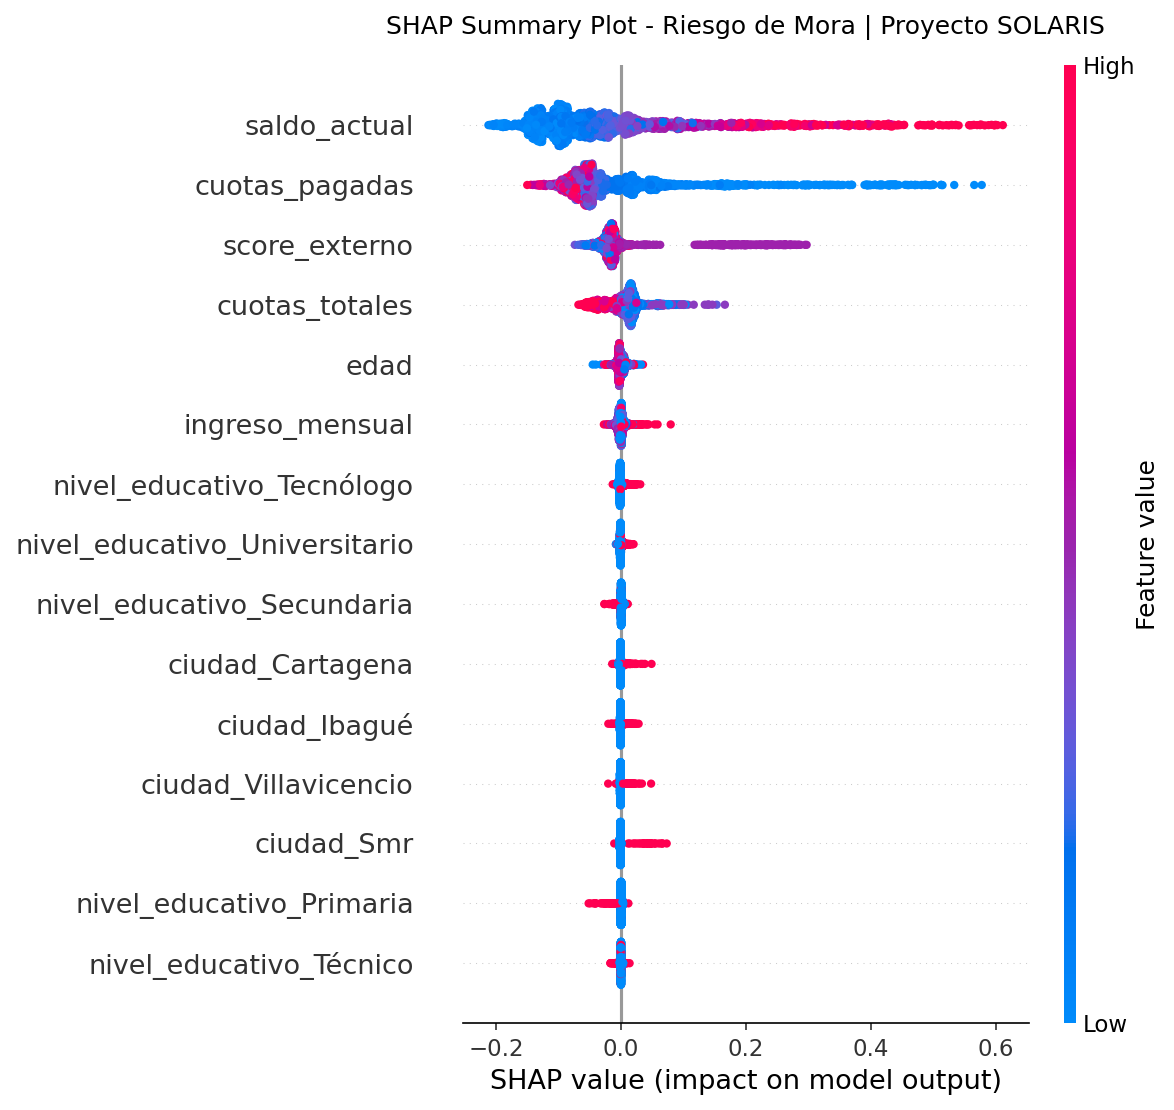

Summary Plot guardado en: c:\Users\anaso\Downloads\proyecto-solaris\reports\figures\shap_summary_plot.png


In [19]:
summary_path = REPORTS_FIGURES / "shap_summary_plot.png"

plt.figure()

shap.summary_plot(
    shap_values,
    X_test_shap_plot,
    plot_type="dot",
    max_display=15,
    show=False
)

plt.title(
    "SHAP Summary Plot - Riesgo de Mora | Proyecto SOLARIS",
    fontsize=12,
    pad=15
)

plt.tight_layout()

plt.savefig(
    summary_path,
    bbox_inches="tight",
    dpi=150
)

plt.show()

print("Summary Plot guardado en:", summary_path)

### Interpretación del Summary Plot

El análisis global mediante SHAP muestra que las variables con mayor influencia en la predicción de mora del modelo SOLARIS son `saldo_actual`, `cuotas_pagadas`, `score_externo` y `cuotas_totales`.

La variable más determinante es `saldo_actual`. Los valores elevados se concentran principalmente en valores SHAP positivos, indicando que un saldo actual alto tiende a incrementar la predicción de riesgo de mora. Por el contrario, los saldos bajos tienden a reducirla.

`cuotas_pagadas` presenta un comportamiento inverso: los clientes con pocas cuotas pagadas muestran contribuciones SHAP positivas y, por tanto, mayor riesgo predicho, mientras que un mayor número de cuotas pagadas tiende a reducir dicho riesgo.

`score_externo` también presenta una influencia relevante en las predicciones del modelo, aunque considerablemente menor que `saldo_actual` y `cuotas_pagadas`. Debido a que esta variable proviene de una fuente externa, su composición debe documentarse para comprender qué información está aportando al modelo.

Las variables `edad` e `ingreso_mensual` muestran una influencia considerablemente menor, mientras que las categorías asociadas al nivel educativo y a la ciudad tienen efectos relativamente pequeños frente a las variables directamente relacionadas con la situación financiera y el comportamiento de pago.

En términos de negocio, el modelo está basando principalmente sus decisiones en el nivel de deuda actual y en el avance que el distribuidor ha realizado en el pago de sus obligaciones.

4. Seleccionar el distribuidor con mayor probabilidad de mora

In [20]:
probabilidades = modelo.predict_proba(X_test)[:, 1]

indice_caso = probabilidades.argmax()
probabilidad_caso = probabilidades[indice_caso]

print("Posición del caso seleccionado:", indice_caso)
print(f"Probabilidad predicha de mora: {probabilidad_caso:.4f}")
print(f"Probabilidad predicha de mora: {probabilidad_caso:.2%}")

Posición del caso seleccionado: 1101
Probabilidad predicha de mora: 0.9737
Probabilidad predicha de mora: 97.37%


In [21]:
print("Datos originales del distribuidor seleccionado:")
display(X_test.iloc[indice_caso].to_frame(name="Valor"))

Datos originales del distribuidor seleccionado:


,Valor
edad,48.0
ingreso_mensual,2224968
saldo_actual,27856913
cuotas_pagadas,0
cuotas_totales,48
score_externo,NaN
nivel_educativo,Universitario
ciudad,Barranquilla


5. Obtener el valor base de la clase Moroso

In [22]:
print("Expected value completo:", explainer.expected_value)

expected_values = np.asarray(explainer.expected_value)

if expected_values.ndim == 0:
    base_value = float(expected_values)
else:
    base_value = float(expected_values[1])

print("Valor base para Moroso = 1:", base_value)

Expected value completo: [0.85376677 0.14623323]
Valor base para Moroso = 1: 0.14623323170731695


6. Verificar la propiedad aditiva antes de graficar

In [23]:
prediccion_reconstruida = (
    base_value
    + shap_values[indice_caso].sum()
)

print(f"Probabilidad del modelo:       {probabilidad_caso:.6f}")
print(f"Base + suma de SHAP values:    {prediccion_reconstruida:.6f}")

print(
    "¿Coinciden?",
    np.isclose(
        probabilidad_caso,
        prediccion_reconstruida,
        atol=1e-6
    )
)

Probabilidad del modelo:       0.973688
Base + suma de SHAP values:    0.973688
¿Coinciden? True


7. Construir el shap.Explanation

In [24]:
explicacion_caso = shap.Explanation(
    values=shap_values[indice_caso],
    base_values=base_value,
    data=X_test_shap.iloc[indice_caso].values,
    feature_names=X_test_shap_plot.columns.tolist()
)

print("Explicación individual construida correctamente.")

Explicación individual construida correctamente.


8. Crear el Waterfall Plot

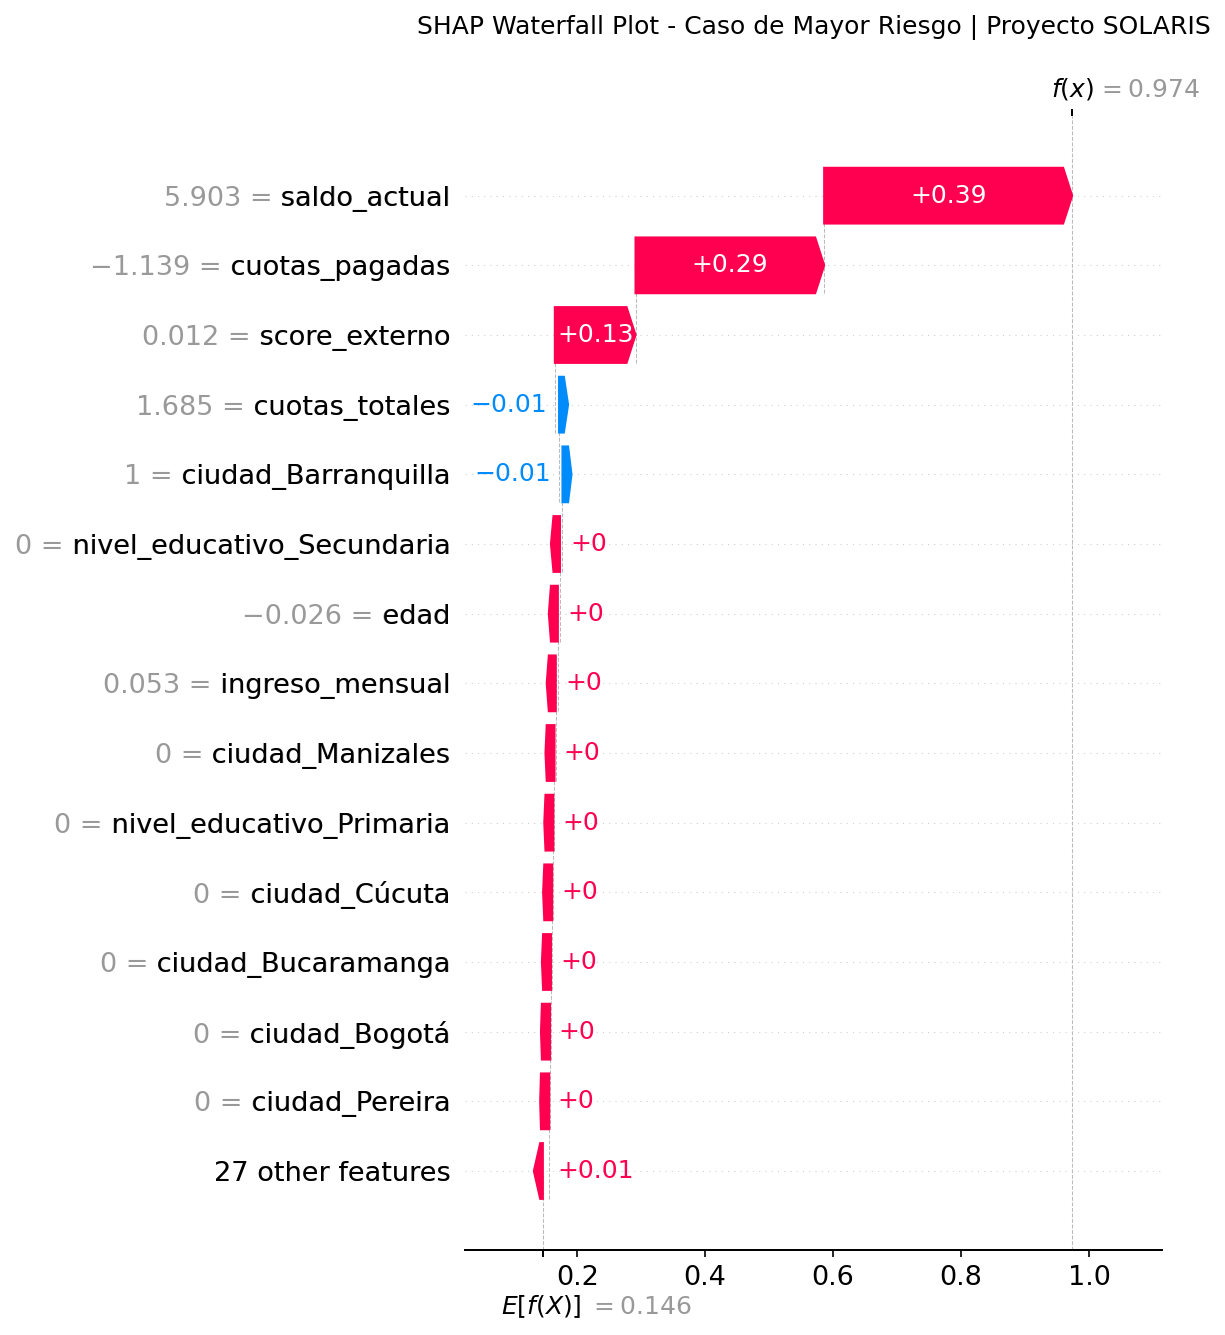

Waterfall Plot guardado en: c:\Users\anaso\Downloads\proyecto-solaris\reports\figures\shap_waterfall_plot.png


In [25]:
waterfall_path = REPORTS_FIGURES / "shap_waterfall_plot.png"

shap.plots.waterfall(
    explicacion_caso,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Waterfall Plot - Caso de Mayor Riesgo | Proyecto SOLARIS",
    fontsize=12,
    pad=20
)

plt.tight_layout()

plt.savefig(
    waterfall_path,
    bbox_inches="tight",
    dpi=150
)

plt.show()

print("Waterfall Plot guardado en:", waterfall_path)

9. Construir los Dependence Plots de las 2 variables más importantes

In [26]:
shap_array = shap_values

importancia_media = np.abs(shap_array).mean(axis=0)

importancia_df = pd.DataFrame({
    "variable": X_test_shap_plot.columns,
    "importancia_shap": importancia_media
}).sort_values(
    "importancia_shap",
    ascending=False
).reset_index(drop=True)

var1 = importancia_df.loc[0, "variable"]
var2 = importancia_df.loc[1, "variable"]

print("Variable más importante:", var1)
print("Segunda variable más importante:", var2)

display(importancia_df.head(10))

Variable más importante: saldo_actual
Segunda variable más importante: cuotas_pagadas


,variable,importancia_shap
0,saldo_actual,0.108799
1,cuotas_pagadas,0.071980
2,score_externo,0.035644
3,cuotas_totales,0.022161
4,edad,0.004350
5,ingreso_mensual,0.003666
6,nivel_educativo_Tecnólogo,0.002719
7,nivel_educativo_Universitario,0.001748
8,nivel_educativo_Secundaria,0.001613
9,ciudad_Cartagena,0.001350


In [27]:
X_test_display = X_test_shap_plot.copy()

variables_numericas = [
    "edad",
    "ingreso_mensual",
    "saldo_actual",
    "cuotas_pagadas",
    "cuotas_totales",
    "score_externo"
]

for variable in variables_numericas:
    if variable in X_test_display.columns:
        X_test_display[variable] = X_test[variable].values

print("Datos preparados para visualización.")

Datos preparados para visualización.


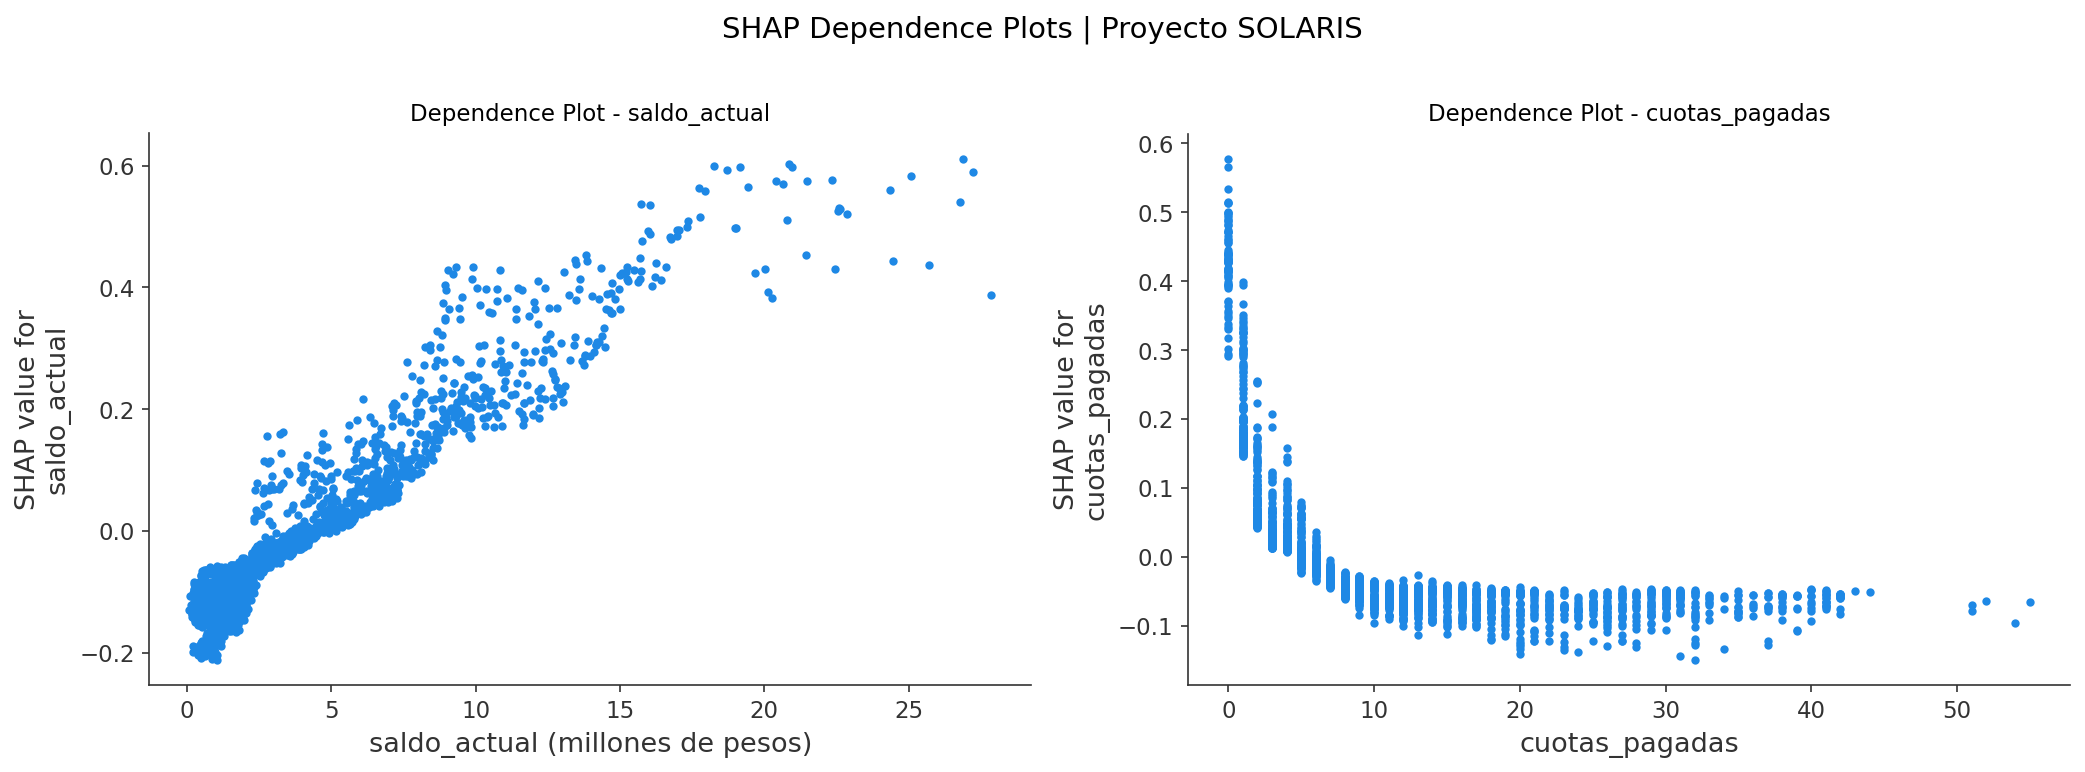

Dependence Plots guardados en: c:\Users\anaso\Downloads\proyecto-solaris\reports\figures\shap_dependence_plots.png


In [35]:
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

shap.dependence_plot(
    var1,
    shap_array,
    X_test_display,
    interaction_index=None,
    ax=axes[0],
    show=False
)

axes[0].set_title(
    f"Dependence Plot - {var1}",
    fontsize=11
)

# Mostrar saldo_actual en millones de pesos
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x/1e6:.0f}")
)

axes[0].set_xlabel(
    "saldo_actual (millones de pesos)"
)

shap.dependence_plot(
    var2,
    shap_array,
    
    X_test_display,
    interaction_index=None,
    ax=axes[1],
    show=False
)

axes[1].set_title(
    f"Dependence Plot - {var2}",
    fontsize=11
)

fig.suptitle(
    "SHAP Dependence Plots | Proyecto SOLARIS",
    fontsize=14,
    y=1.02
)

plt.tight_layout()

dependence_path = (
    REPORTS_FIGURES
    / "shap_dependence_plots.png"
)

plt.savefig(
    dependence_path,
    bbox_inches="tight",
    dpi=150
)

plt.show()
print("Dependence Plots guardados en:", dependence_path)

### Interpretación de los Dependence Plots

Los gráficos de dependencia confirman que las dos variables de mayor importancia global presentan relaciones claras con la predicción de mora.

En `saldo_actual` se observa una relación creciente: los saldos bajos presentan contribuciones SHAP negativas, mientras que a medida que aumenta el saldo pendiente, la contribución hacia la clase Moroso se vuelve positiva y aumenta progresivamente. Esto indica que el modelo considera un mayor saldo actual como una señal relevante de mayor riesgo de mora.

Por su parte, `cuotas_pagadas` presenta una relación inversa. Los distribuidores con pocas cuotas pagadas muestran contribuciones SHAP fuertemente positivas, mientras que el impacto disminuye rápidamente conforme aumenta el número de cuotas pagadas. Después de aproximadamente 6 a 8 cuotas, la contribución tiende a ser negativa y se estabiliza, sugiriendo que un mayor avance en el pago reduce el riesgo estimado por el modelo.

Los resultados muestran además relaciones no lineales, especialmente en `cuotas_pagadas`, donde las primeras cuotas generan cambios mucho mayores en la predicción que las cuotas adicionales una vez que el cliente ya ha avanzado considerablemente en su obligación.

10. Verificar si hay sesgos revelados

In [29]:
# Importancia SHAP media por columna transformada
importancia_columnas = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_test_shap_plot.columns
)

def variable_original(nombre):
    if nombre.startswith("nivel_educativo_"):
        return "nivel_educativo"
    elif nombre.startswith("ciudad_"):
        return "ciudad"
    else:
        return nombre

importancia_agrupada = (
    importancia_columnas
    .groupby([variable_original(col) for col in importancia_columnas.index])
    .sum()
    .sort_values(ascending=False)
    .to_frame("importancia_SHAP_media")
)

display(importancia_agrupada)

,importancia_SHAP_media
saldo_actual,0.108799
cuotas_pagadas,0.071980
score_externo,0.035644
cuotas_totales,0.022161
ciudad,0.017196
nivel_educativo,0.009009
edad,0.004350
ingreso_mensual,0.003666


10.1 Identificar qué atributos sensibles existen realmente

In [30]:
atributos_protegidos_posibles = [
    "genero",
    "sexo",
    "raza",
    "etnia",
    "estrato"
]

presentes = [
    col for col in atributos_protegidos_posibles
    if col in df_modelo.columns
]

print("Atributos protegidos disponibles:", presentes)

print("\nVariables demográficas o potencialmente sensibles disponibles:")
print([
    col for col in [
        "edad",
        "ingreso_mensual",
        "nivel_educativo",
        "ciudad"
    ]
    if col in df_modelo.columns
])

Atributos protegidos disponibles: []

Variables demográficas o potencialmente sensibles disponibles:
['edad', 'ingreso_mensual', 'nivel_educativo', 'ciudad']


10.2. Correlaciones con mora y con la probabilidad predicha

In [31]:
auditoria_sesgo = X_test.copy()

auditoria_sesgo["mora_real"] = y_test.values
auditoria_sesgo["prob_mora"] = probabilidades

variables_numericas_auditoria = [
    "edad",
    "ingreso_mensual",
    "saldo_actual",
    "cuotas_pagadas",
    "cuotas_totales",
    "score_externo",
    "mora_real",
    "prob_mora"
]

correlaciones = (
    auditoria_sesgo[variables_numericas_auditoria]
    .corr()
)

display(
    correlaciones[
        ["mora_real", "prob_mora"]
    ].sort_values(
        "prob_mora",
        ascending=False
    )
)

,mora_real,prob_mora
prob_mora,0.784925,1.000000
mora_real,1.000000,0.784925
saldo_actual,0.500624,0.654520
score_externo,-0.000472,0.037320
cuotas_totales,-0.002173,0.021916
ingreso_mensual,-0.016480,-0.022202
edad,-0.030054,-0.037028
cuotas_pagadas,-0.272287,-0.368780


10.3. Auditar edad por grupos

In [32]:
auditoria_sesgo["rango_edad"] = pd.cut(
    auditoria_sesgo["edad"],
    bins=[0, 29, 39, 49, 59, 69, 120],
    labels=[
        "≤29",
        "30-39",
        "40-49",
        "50-59",
        "60-69",
        "70+"
    ]
)

auditoria_edad = (
    auditoria_sesgo
    .groupby("rango_edad", observed=False)
    .agg(
        n=("mora_real", "size"),
        tasa_mora_real=("mora_real", "mean"),
        prob_mora_media=("prob_mora", "mean")
    )
)

auditoria_edad["brecha"] = (
    auditoria_edad["prob_mora_media"]
    - auditoria_edad["tasa_mora_real"]
)

display(auditoria_edad)

,n,tasa_mora_real,prob_mora_media,brecha
rango_edad,,,,
≤29,454,0.149780,0.149357,-0.000423
30-39,363,0.157025,0.155941,-0.001083
40-49,334,0.158683,0.148689,-0.009994
50-59,384,0.169271,0.159109,-0.010161
60-69,377,0.135279,0.131336,-0.003943
70+,370,0.116216,0.124781,0.008565


10.4 Auditar nivel educativo

In [33]:
auditoria_educacion = (
    auditoria_sesgo
    .groupby("nivel_educativo")
    .agg(
        n=("mora_real", "size"),
        tasa_mora_real=("mora_real", "mean"),
        prob_mora_media=("prob_mora", "mean")
    )
    .sort_values(
        "prob_mora_media",
        ascending=False
    )
)

auditoria_educacion["brecha"] = (
    auditoria_educacion["prob_mora_media"]
    - auditoria_educacion["tasa_mora_real"]
)

display(auditoria_educacion)

,n,tasa_mora_real,prob_mora_media,brecha
nivel_educativo,,,,
Posgrado,188,0.154255,0.151307,-0.002948
Tecnólogo,429,0.139860,0.150755,0.010894
Universitario,592,0.158784,0.148897,-0.009887
Primaria,145,0.144828,0.142129,-0.002699
Técnico,499,0.136273,0.141191,0.004919
Secundaria,607,0.144975,0.136107,-0.008868


10.5. Auditar ciudad

In [34]:
mapa_ciudades = {
    "Bog": "Bogotá",
    "Bta": "Bogotá",

    "Mdl": "Medellín",
    "Med.": "Medellín",

    "Baq": "Barranquilla",
    "B/Quilla": "Barranquilla",
    "Barranqilla": "Barranquilla",

    "Bga": "Bucaramanga",
    "B/Manga": "Bucaramanga",

    "Cal": "Cali",
    "Santiago De Cali": "Cali",

    "San José De Cúcuta": "Cúcuta",

    "Mzl": "Manizales",

    "Pei": "Pereira",

    "Smr": "Santa Marta",
    "Sta Marta": "Santa Marta",

    "Villavo": "Villavicencio"
}

auditoria_sesgo["ciudad_auditoria"] = (
    auditoria_sesgo["ciudad"]
    .replace(mapa_ciudades)
)

auditoria_ciudad = (
    auditoria_sesgo
    .groupby("ciudad_auditoria")
    .agg(
        n=("mora_real", "size"),
        tasa_mora_real=("mora_real", "mean"),
        prob_mora_media=("prob_mora", "mean")
    )
    .sort_values(
        "prob_mora_media",
        ascending=False
    )
)

auditoria_ciudad["brecha"] = (
    auditoria_ciudad["prob_mora_media"]
    - auditoria_ciudad["tasa_mora_real"]
)

display(auditoria_ciudad)

,n,tasa_mora_real,prob_mora_media,brecha
ciudad_auditoria,,,,
Cali,205,0.141463,0.158928,0.017465
Manizales,218,0.169725,0.156346,-0.013379
Medellín,217,0.138249,0.155678,0.017429
Pereira,214,0.172897,0.155487,-0.017410
Bucaramanga,194,0.170103,0.148284,-0.021819
Bogotá,225,0.160000,0.148120,-0.011880
Villavicencio,191,0.109948,0.146993,0.037046
Barranquilla,202,0.148515,0.145266,-0.003249
Cúcuta,200,0.165000,0.135017,-0.029983


### Auditoría exploratoria de posibles sesgos y variables proxy

El dataset de SOLARIS no contiene atributos protegidos explícitos como género, raza, etnia o estrato socioeconómico. Por esta razón, no es posible comprobar directamente si el modelo discrimina a estos grupos. Sin embargo, se revisaron las variables con mayor importancia SHAP y aquellas que podrían actuar como proxies de características demográficas, socioeconómicas o geográficas.

| Variable con alto SHAP | Posible proxy de | Evidencia | Conclusión |
|---|---|---|---|
| `saldo_actual` | No se identifica un proxy directo; representa exposición financiera | Es la variable más importante del modelo, con importancia SHAP media de **0.1088**. Presenta una correlación de **0.6545** con la probabilidad predicha de mora y de **0.5006** con la mora real. Su relación es directamente financiera y coherente con el objetivo del modelo. | **Riesgo bajo** |
| `cuotas_pagadas` | No se identifica un proxy directo; representa comportamiento de pago | Es la segunda variable más importante, con SHAP medio de **0.0720**. Su correlación con la probabilidad de mora es **-0.3688**, mostrando que un mayor avance en los pagos reduce el riesgo estimado. | **Riesgo bajo** |
| `score_externo` | Podría incorporar indirectamente variables socioeconómicas o demográficas | Es la tercera variable más importante, con SHAP medio de **0.0356**. Su correlación lineal con la probabilidad de mora es baja (**0.0373**), pero no se conoce la composición ni las variables utilizadas para construir el score externo. | **Riesgo medio — prioridad de revisión** |
| `cuotas_totales` | No se identifica un proxy directo; característica contractual del crédito | Tiene una importancia SHAP media de **0.0222** y una correlación muy baja con la probabilidad de mora (**0.0219**). No se observan indicios claros de que represente un atributo protegido. | **Riesgo bajo** |
| `ciudad` | Ubicación geográfica, nivel socioeconómico u otras características históricamente asociadas al territorio | Su importancia SHAP agrupada es **0.0172**. Se observan diferencias entre mora real y probabilidad media predicha: Villavicencio presenta una brecha de **+3.70 p.p.**, Cúcuta de **-3.00 p.p.** y Bucaramanga de **-2.18 p.p.**. Además, originalmente existían múltiples formas de registrar una misma ciudad. | **Riesgo medio** |
| `nivel_educativo` | Nivel socioeconómico u oportunidades económicas | Su importancia SHAP agrupada es **0.0090**. Las diferencias entre la tasa real y la probabilidad predicha son reducidas: la mayor brecha positiva se observa en Tecnólogo (**+1.09 p.p.**) y la mayor negativa en Universitario (**-0.99 p.p.**). | **Riesgo medio** |
| `edad` | Característica demográfica directa | Presenta una importancia SHAP baja (**0.0044**) y una correlación de solo **-0.0370** con la probabilidad de mora. Las brechas por grupos de edad son pequeñas, aproximadamente entre **-1.02 y +0.86 p.p.** | **Riesgo medio** |
| `ingreso_mensual` | Nivel socioeconómico o estrato | Tiene la menor importancia SHAP entre las variables analizadas (**0.0037**) y una correlación baja con la probabilidad de mora (**-0.0222**). No se observa una señal fuerte de influencia en las decisiones del modelo. | **Riesgo bajo** |

### Conclusión de la auditoría de sesgo

La auditoría exploratoria no muestra evidencia suficiente para afirmar que el modelo SOLARIS esté tomando decisiones discriminatorias. Las variables con mayor influencia corresponden principalmente a características financieras y de comportamiento de pago, especialmente `saldo_actual` y `cuotas_pagadas`.

Las variables demográficas y socioeconómicas presentan una influencia considerablemente menor. La edad muestra una correlación muy baja con la probabilidad predicha y las diferencias entre rangos etarios son reducidas. De forma similar, las diferencias observadas entre niveles educativos son pequeñas.

No obstante, se identifican dos aspectos que requieren monitoreo. Primero, la variable `ciudad` presenta diferencias de hasta aproximadamente 3.7 puntos porcentuales entre la tasa de mora observada y la probabilidad media predicha en algunos grupos, por lo que debe vigilarse como posible proxy geográfico. Segundo, `score_externo` tiene una importancia relevante dentro del modelo, pero no se dispone de información sobre las variables utilizadas en su construcción, lo que impide descartar que contenga indirectamente información socioeconómica o demográfica.

La principal limitación del análisis es que el dataset no contiene atributos protegidos explícitos como género, raza, etnia o estrato socioeconómico. Por tanto, los resultados permiten identificar riesgos potenciales de proxy, pero no demostrar ni descartar completamente la existencia de discriminación.

Se recomienda documentar el origen y composición de `score_externo`, mantener normalizadas las categorías de `ciudad` y monitorear periódicamente las tasas de predicción y de error entre grupos demográficos, educativos y geográficos.

## Narrativa ejecutiva de interpretabilidad — Proyecto SOLARIS

### 1. ¿Qué aprendió el modelo?

El modelo SOLARIS aprendió que el riesgo de mora está explicado principalmente por la situación actual de la deuda y por el avance que el distribuidor ha realizado en sus pagos. El factor más determinante es el `saldo_actual`: a medida que aumenta el saldo pendiente, el modelo tiende a considerar mayor el riesgo de mora. El segundo factor es `cuotas_pagadas`: haber pagado pocas cuotas incrementa de forma importante el riesgo estimado, mientras que avanzar en los pagos lo reduce. El `score_externo` es el tercer factor con mayor influencia, por lo que aporta información relevante a la decisión, aunque su origen y composición deben documentarse para garantizar su adecuada interpretación.

### 2. ¿Por qué debería confiar en él?

El modelo fue evaluado sobre un conjunto de prueba independiente que no se utilizó durante el entrenamiento y alcanzó un ROC-AUC aproximado de 0.959 y una exactitud del 93.6%, mostrando una alta capacidad para diferenciar distribuidores de mayor y menor riesgo. Además, las explicaciones SHAP permiten identificar qué factores intervienen tanto en el comportamiento general del modelo como en cada decisión individual, evitando que el resultado funcione como una “caja negra”. Sin embargo, el recall de la clase Moroso es aproximadamente 62.8%, por lo que el modelo todavía puede dejar pasar algunos distribuidores que posteriormente presentan mora y debe utilizarse como apoyo a la decisión, acompañado de revisión y monitoreo.

### 3. Ejemplo de explicación para un caso individual

El distribuidor identificado por SOLARIS con mayor riesgo obtuvo una probabilidad de mora del **97.37%**, frente a un riesgo promedio del modelo de aproximadamente **14.62%**. El principal factor que elevó esta predicción fue un `saldo_actual` de aproximadamente **$27.9 millones**, que aportó cerca de **39 puntos porcentuales** adicionales al riesgo estimado. El distribuidor identificado por SOLARIS con mayor riesgo obtuvo una probabilidad de mora del **97.37%**, frente a un riesgo promedio del modelo de aproximadamente **14.62%**. El principal factor que elevó esta predicción fue un `saldo_actual` de aproximadamente **$27.9 millones**, que aportó cerca de **39 puntos porcentuales** adicionales al riesgo estimado. El hecho de tener **0 cuotas pagadas** añadió aproximadamente **29 puntos porcentuales**. En este caso, el `score_externo` original se encontraba ausente, por lo que el pipeline lo imputó automáticamente antes de realizar la predicción; su valor procesado aportó cerca de **13 puntos adicionales**. En conjunto, estos factores explican por qué el modelo considera a este distribuidor un caso de riesgo especialmente alto.

### 4. ¿Hay riesgos de sesgo?

La auditoría realizada no aporta evidencia suficiente para afirmar que SOLARIS esté tomando decisiones discriminatorias: las variables con mayor influencia corresponden principalmente a deuda y comportamiento de pago, y variables como edad o ingreso tienen un peso reducido. Sin embargo, `ciudad` debe mantenerse bajo monitoreo porque se observaron diferencias de hasta aproximadamente **3.7 puntos porcentuales** entre la tasa real de mora y la probabilidad media predicha en algunos grupos, y la ubicación podría funcionar como proxy de condiciones socioeconómicas. También es necesario revisar la construcción de `score_externo`, ya que es una variable relevante para el modelo y actualmente no se conoce qué información fue utilizada para calcularlo.